### 解析网页
---


In [1]:
! pip install -qU langchain-community beautifulsoup4 unstructured


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ! pip install -qU langchain-unstructured
! pip install langchain-community playwright
! playwright install

   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/38.8 MB ? eta -:--:--
    --------------------------------------- 0.5/38.8 MB 966.4 kB/s eta 0:00:40
    --------------------------------------- 0.5/38.8 MB 966.4 kB/s eta 0:00:40
    --------------------------------------- 0.8/38.8 MB 784.4 kB/s eta 0:00:49
   - -------------------------------------- 1.0/38.8 MB 842.8 kB/s eta 0:00:45
   - -------------------------------------- 1.0/38.8 MB 842.8 kB/s eta 0:00:45
   - -------------------------------------- 1.3/38.8 MB 775.2 kB/s eta 0:00:49
   - -------------------------------------- 1.3/38.8 MB 775.2 kB/s eta 0:00:49
   - -------------------------------------- 1.3/38.8 MB 775.2 kB/s eta 0:00:49
   - -------------------------------------- 1.3/38.8 MB 775.2 kB/s eta 0:00:49
   - ----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
'playwright' �����ڲ����ⲿ���Ҳ���ǿ����еĳ���
���������ļ���


In [18]:
from langchain_community.document_loaders import WebBaseLoader
import bs4 # 导入 beautifulsoup4 解析网页

page_url = "https://reference.langchain.com/python/langchain-classic/chains/retrieval/create_retrieval_chain"

loader = WebBaseLoader(web_paths=[page_url])
docs = []
async for doc in loader.alazy_load():
    docs.append(doc)

assert len(docs) == 1
doc = docs[0]

Fetching pages: 100%|##########| 1/1 [00:01<00:00,  1.21s/it]


In [19]:
print(f"{doc.metadata}\n")
print(doc.page_content[:500].strip())

{'source': 'https://reference.langchain.com/python/langchain-classic/chains/retrieval/create_retrieval_chain', 'title': 'create_retrieval_chain | langchain_classic | LangChain Reference', 'description': 'Python API reference for chains.retrieval.create_retrieval_chain in langchain_classic. Part of the LangChain ecosystem.', 'language': 'en'}

create_retrieval_chain | langchain_classic | LangChain ReferenceLangChain Reference home pageSearch...⌘KAsk AIGitHubMain DocsDeep AgentsLangChainLangGraphIntegrationsLangSmithOverviewLangChainLangChain CoreMCP AdaptersStandard TestsText SplittersLangChain ClassicOverviewAgentsCallbacksChainsChat modelsEmbeddingsEvaluationGlobalsHubMemoryOutput parsersRetrieversRunnablesLangSmithStorage⌘IChat LangChainWhat can I help with?Enter to send·Shift+Enter new lineWhat are deep agents and how do I get sta


In [26]:
from langchain_community.document_loaders import WebBaseLoader
import os

# 设置 User-Agent 伪装成真实浏览器，防止被网站拦截
os.environ["USER_AGENT"] = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"

page_url = "https://reference.langchain.com/python/langchain-classic/chains/retrieval/create_retrieval_chain"
loader = WebBaseLoader(web_paths=[page_url])

# WebBaseLoader 支持同步的 lazy_load
docs = list(loader.lazy_load())

assert len(docs) == 1
doc = docs[0]

print("✅ 抓取成功！内容预览：")
print(doc.page_content[:500])

✅ 抓取成功！内容预览：
create_retrieval_chain | langchain_classic | LangChain ReferenceLangChain Reference home pageSearch...⌘KAsk AIGitHubMain DocsDeep AgentsLangChainLangGraphIntegrationsLangSmithOverviewLangChainLangChain CoreMCP AdaptersStandard TestsText SplittersLangChain ClassicOverviewAgentsCallbacksChainsChat modelsEmbeddingsEvaluationGlobalsHubMemoryOutput parsersRetrieversRunnablesLangSmithStorage⌘IChat LangChainWhat can I help with?Enter to send·Shift+Enter new lineWhat are deep agents and how do I get sta


指定加载网页的某一部分

In [28]:
loader = WebBaseLoader(
    web_paths=[page_url],
    bs_kwargs={
        "parse_only": bs4.SoupStrainer(class_="shiki shiki-themes github-light github-dark bg-white dark:bg-[#24292e] p-4 m-0 text-sm overflow-x-auto rounded-lg")
    },
    bs_get_text_kwargs={"separator": " | ", "strip": True},
)

docs = []
async for doc in loader.alazy_load():
    docs.append(doc)

assert len(docs) == 1
doc = docs[0]

Fetching pages: 100%|##########| 1/1 [00:01<00:00,  1.60s/it]


In [29]:
print(f"{doc.metadata}\n")
print(doc.page_content[:500])

{'source': 'https://reference.langchain.com/python/langchain-classic/chains/retrieval/create_retrieval_chain'}

create_retrieval_chain | ( | retriever | : | BaseRetriever | | | Runnable | [ | dict | , | RetrieverOutput | ] | , | combine_docs_chain | : | Runnable | [


高级：不熟悉网页结构的情况下解析网页

In [ ]:
from langchain_unstructured import UnstructuredLoader
# UnstructuredLoader 主要是为了解析本地文件（如 PDF、Word、本地 HTML 文件等）而设计的。

page_url = "https://reference.langchain.com/python/langchain-classic/chains/retrieval/create_retrieval_chain"
loader = UnstructuredLoader(web_url=page_url)

docs=[]
async for doc in loader.alazy_load():
    docs.append(doc)

for doc in docs[:5]:
    print(doc.page_content)

### 加载CSV
---

In [1]:
from langchain_community.document_loaders.csv_loader import CSVLoader

file_path="charts.csv"

loader = CSVLoader(file_path=file_path, encoding="utf-8")
data = loader.load()

for record in data[:2]:
    print(record)

C:\Users\Lxb\AppData\Local\Temp\ipykernel_73480\2264288395.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders.csv_loader import CSVLoader


page_content='No: 1
Data Type: Trend Over Time
Keywords: trend, time-series, line, growth, timeline, progress
Best Chart Type: Line Chart
Secondary Options: Area Chart, Smooth Area
Color Guidance: Primary: #0080FF. Multiple series: use distinct colors. Fill: 20% opacity
Performance Impact: ⚡ Excellent (optimized)
Accessibility Notes: ✓ Clear line patterns for colorblind users. Add pattern overlays.
Library Recommendation: Chart.js, Recharts, ApexCharts
Interactive Level: Hover + Zoom' metadata={'source': 'charts.csv', 'row': 0}
page_content='No: 2
Data Type: Compare Categories
Keywords: compare, categories, bar, comparison, ranking
Best Chart Type: Bar Chart (Horizontal or Vertical)
Secondary Options: Column Chart, Grouped Bar
Color Guidance: Each bar: distinct color. Category: grouped same color. Sorted: descending order
Performance Impact: ⚡ Excellent
Accessibility Notes: ✓ Easy to compare. Add value labels on bars for clarity.
Library Recommendation: Chart.js, Recharts, D3.js
Intera

### 解析excel
---
使用微软云的Document intelligence服务来解析，需要申请KEY

In [8]:
! pip install --upgrade --quiet langchain langchain-community azure-ai-documentintelligence


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
from langchain_community.document_loaders import AzureAIDocumentIntelligenceLoader

file_path = "fake.xlsx"
endpoint = "https://jiaoxue.congnitiveservices.azure.com/"
key = "<REDACTED>"

loader = AzureAIDocumentIntelligenceLoader(
    api_endpoint=endpoint, api_key=key, file_path=file_path, api_model="prebuilt-layout"
)

documents = loader.load()

ServiceRequestError: [SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1082)

### 自定义文档加载器
---
一个文档加载器包含的主要方法
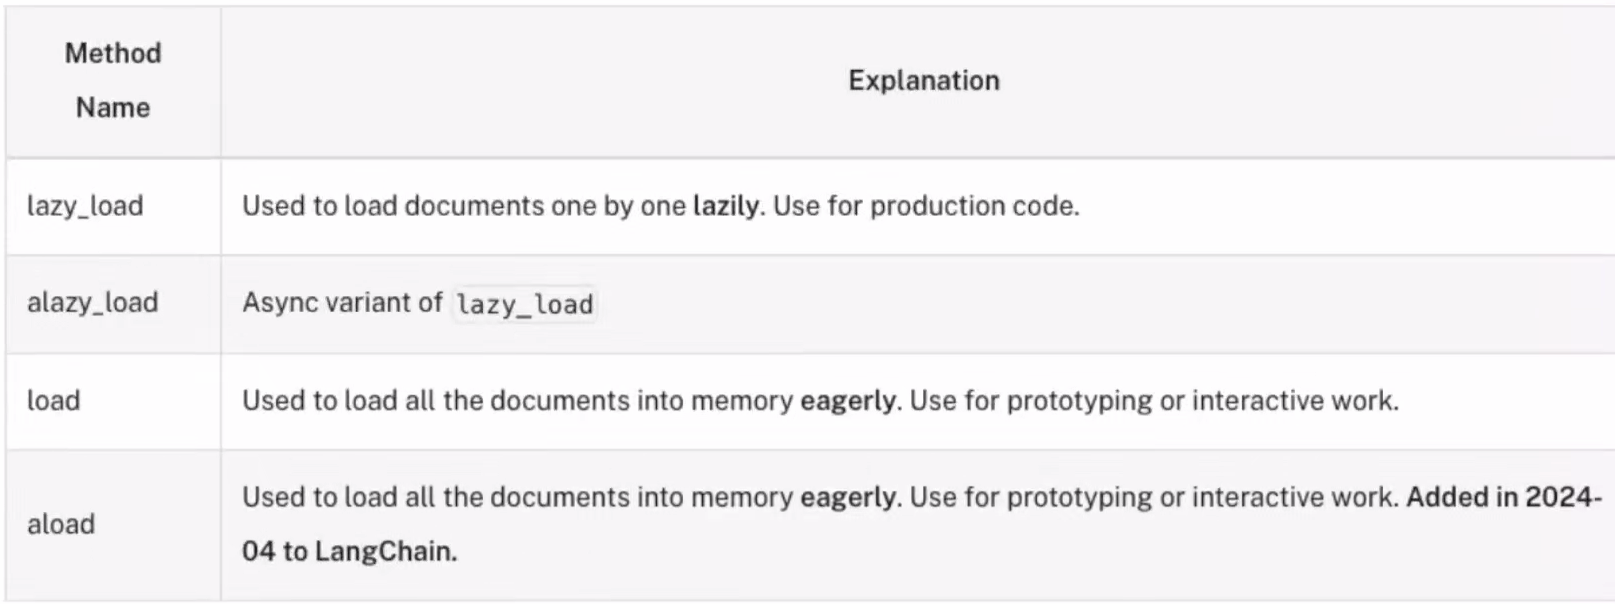

In [2]:
! pip install aiofiles


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from typing import AsyncIterator, Iterator
from langchain_core.document_loaders import BaseLoader
from langchain_core.documents import Document

class CustomDocumentLoader(BaseLoader):
    """逐行读取文件的文档加载器示例"""

    def __init__(self, file_path: str) -> None:
        """
            使用文件路径初始化加载器

            参数：
                file_path：要加载的文件路径
        """
        self.file_path = file_path

    def lazy_load(self) -> Iterator[Document]:
        """
            逐行读取文件的惰性加载器

            当实现惰性加载方法时，你应该使用生成器
            一次生成一个文档
        """

        with open(self.file_path, encoding="utf-8") as f:
            line_number = 0;
            for line in f:
                yield Document(
                    page_content=line,
                    metadata={"line_number": line_number, "source": self.file_path},
                )
                line_number += 1

        # alazy_load 是可选的
        # 如果不实现它，将使用一个默认实现，该实现会委托给 lazy_load!
        async def alazy_load(self) -> AsyncIterator[Document]:
            """逐行读取文件的异步惰性加载器"""
            # 需要 aiofiles (通过pip安装)
            # https://github.com/Tinche/aiofiles

            import aiofiles

            async with aiofiles.open(self.file_path, encoding="utf-8") as f:
                line_number = 0
                async for line in f:
                    yield Document(
                        page_content=line,
                        metadata={"line_number": line_number, "source": self.file_path},
                    )
                    line_number += 1

# 测试
with open("meow.txt", "w", encoding="utf-8") as f:
    quality_content = "meow meow🐱 \n meow meow🐱 \n meow 😍😍"
    f.write(quality_content)

loader = CustomDocumentLoader("meow.txt")

# 测试懒加载
for doc in loader.lazy_load():
    print()
    print(type(doc))
    print(doc)


<class 'langchain_core.documents.base.Document'>
page_content='meow meow🐱 
' metadata={'line_number': 0, 'source': 'meow.txt'}

<class 'langchain_core.documents.base.Document'>
page_content=' meow meow🐱 
' metadata={'line_number': 1, 'source': 'meow.txt'}

<class 'langchain_core.documents.base.Document'>
page_content=' meow 😍😍' metadata={'line_number': 2, 'source': 'meow.txt'}
